In [1]:
import os

data_path = "data/att_faces"

print("Dataset path exists:", os.path.exists(data_path))

if os.path.exists(data_path):
    print("Folders:", os.listdir(data_path)[:10])

Dataset path exists: True
Folders: []


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

Loading and inspecting one face

In [10]:
image_path = Path("data/att_faces/s1/1.pgm")

image = Image.open(image_path).convert("L")
image_array = np.array(image)

print("Image dimensions:", image_array.shape)
print("Minimum intensity:", image_array.min())
print("Maximum intensity:", image_array.max())
print("Data type:", image_array.dtype)

plt.imshow(image_array, cmap="gray")
plt.title("Sample Face Image")
plt.axis("off")
plt.show()

FileNotFoundError: [Errno 2] No such file or directory: 'data\\att_faces\\s1\\1.pgm'

In [4]:
import os

print("Current working directory:", os.getcwd())
print("Files and folders:", os.listdir())

Current working directory: c:\Users\Yashish\OneDrive\Desktop\202618019_JayeshHedaoo_DS605\202618019_LAB07
Files and folders: ['data', 'lab7.ipynb', 'README.md']


In [7]:
from pathlib import Path

data_path = Path("data/att_faces")

print("Dataset folder exists:", data_path.exists())

if data_path.exists():
    print("Contents:", list(data_path.iterdir())[:10])

Dataset folder exists: True
Contents: [WindowsPath('data/att_faces/archive (4)')]


In [8]:
if data_path.exists():
    image_files = list(data_path.rglob("*"))
    image_files = [p for p in image_files if p.is_file()]

    print("Total files:", len(image_files))
    print("First 10 files:", image_files[:10])

Total files: 401
First 10 files: [WindowsPath('data/att_faces/archive (4)/README'), WindowsPath('data/att_faces/archive (4)/s1/1.pgm'), WindowsPath('data/att_faces/archive (4)/s1/10.pgm'), WindowsPath('data/att_faces/archive (4)/s1/2.pgm'), WindowsPath('data/att_faces/archive (4)/s1/3.pgm'), WindowsPath('data/att_faces/archive (4)/s1/4.pgm'), WindowsPath('data/att_faces/archive (4)/s1/5.pgm'), WindowsPath('data/att_faces/archive (4)/s1/6.pgm'), WindowsPath('data/att_faces/archive (4)/s1/7.pgm'), WindowsPath('data/att_faces/archive (4)/s1/8.pgm')]


In [11]:
from pathlib import Path

data_path = Path("data/att_faces")

# Find all subject folders, including nested folders
subject_folders = sorted(data_path.rglob("s*"))

subject_folders = [
    folder for folder in subject_folders
    if folder.is_dir()
    and folder.name[1:].isdigit()
]

print("Number of subject folders:", len(subject_folders))
print("First 10 subject folders:", subject_folders[:10])

Number of subject folders: 40
First 10 subject folders: [WindowsPath('data/att_faces/archive (4)/s1'), WindowsPath('data/att_faces/archive (4)/s10'), WindowsPath('data/att_faces/archive (4)/s11'), WindowsPath('data/att_faces/archive (4)/s12'), WindowsPath('data/att_faces/archive (4)/s13'), WindowsPath('data/att_faces/archive (4)/s14'), WindowsPath('data/att_faces/archive (4)/s15'), WindowsPath('data/att_faces/archive (4)/s16'), WindowsPath('data/att_faces/archive (4)/s17'), WindowsPath('data/att_faces/archive (4)/s18')]


counting the face images

In [12]:
image_extensions = {".pgm", ".png", ".jpg", ".jpeg", ".bmp"}

image_files = [
    file
    for file in data_path.rglob("*")
    if file.is_file() and file.suffix.lower() in image_extensions
]

print("Total face images:", len(image_files))
print("First 5 image paths:", image_files[:5])

Total face images: 400
First 5 image paths: [WindowsPath('data/att_faces/archive (4)/s1/1.pgm'), WindowsPath('data/att_faces/archive (4)/s1/10.pgm'), WindowsPath('data/att_faces/archive (4)/s1/2.pgm'), WindowsPath('data/att_faces/archive (4)/s1/3.pgm'), WindowsPath('data/att_faces/archive (4)/s1/4.pgm')]


Loading ll face images

In [13]:
import numpy as np
from PIL import Image
from pathlib import Path
import matplotlib.pyplot as plt

data_path = Path("data/att_faces")

# Find all image files
image_extensions = {".pgm", ".png", ".jpg", ".jpeg", ".bmp"}

image_files = sorted([
    file for file in data_path.rglob("*")
    if file.is_file() and file.suffix.lower() in image_extensions
])

images = []
labels = []

for file in image_files:
   
    image = Image.open(file).convert("L")

    
    image_array = np.array(image)

    images.append(image_array.flatten())


    subject_name = file.parent.name

    if subject_name.startswith("s") and subject_name[1:].isdigit():
        labels.append(int(subject_name[1:]))
    else:
        continue


X = np.array(images)
y = np.array(labels)

print("Feature matrix shape:", X.shape)
print("Labels shape:", y.shape)
print("Number of subjects:", len(np.unique(y)))
print("Unique subject labels:", np.unique(y))

Feature matrix shape: (400, 10304)
Labels shape: (400,)
Number of subjects: 40
Unique subject labels: [ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24
 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40]


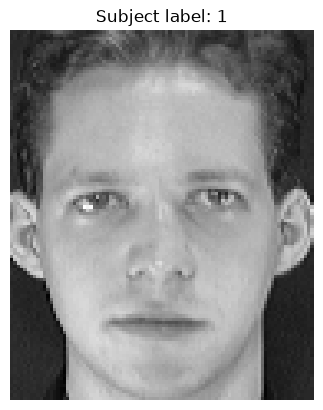

In [14]:
sample_image = X[0].reshape(112, 92)

plt.imshow(sample_image, cmap="gray")
plt.title(f"Subject label: {y[0]}")
plt.axis("off")
plt.show()

Inspect image dimensions and pixel intensities

In [15]:
# Inspect the first image
print("Image matrix shape:", X[0].reshape(112, 92).shape)
print("Minimum pixel intensity:", X.min())
print("Maximum pixel intensity:", X.max())
print("Data type:", X.dtype)

# Display the first 10 pixel values
print("First 10 pixel values:", X[0][:10])

Image matrix shape: (112, 92)
Minimum pixel intensity: 0
Maximum pixel intensity: 251
Data type: uint8
First 10 pixel values: [48 49 45 47 49 57 39 42 53 49]


In [16]:
from sklearn.model_selection import train_test_split

In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print("Training feature matrix:", X_train.shape)
print("Testing feature matrix:", X_test.shape)

print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

print("Subjects in training:", len(np.unique(y_train)))
print("Subjects in testing:", len(np.unique(y_test)))

Training feature matrix: (280, 10304)
Testing feature matrix: (120, 10304)
Training labels: (280,)
Testing labels: (120,)
Subjects in training: 40
Subjects in testing: 40


Visualizing a few training images

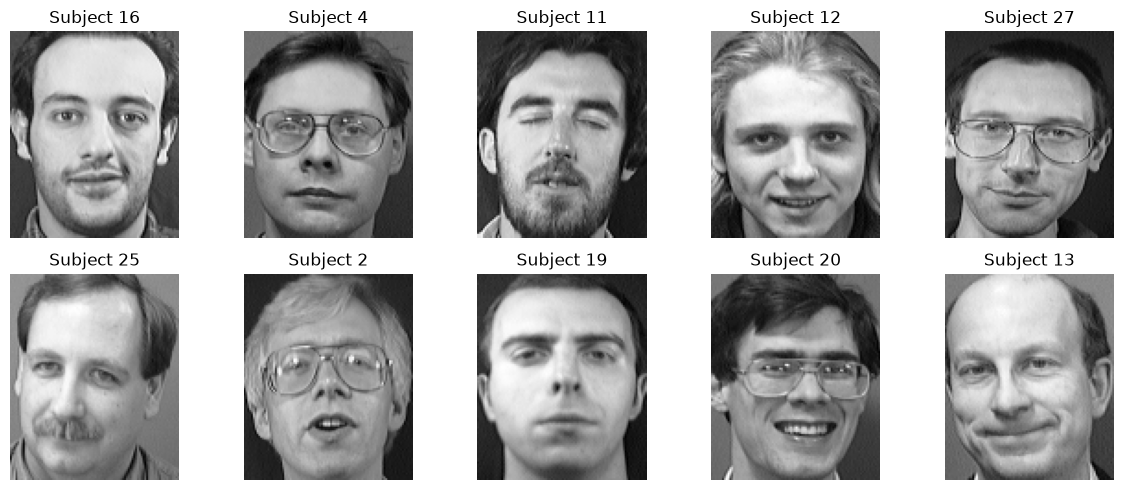

In [18]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    ax.imshow(X_train[i].reshape(112, 92), cmap="gray")
    ax.set_title(f"Subject {y_train[i]}")
    ax.axis("off")

plt.tight_layout()
plt.show()

Part B — PCA and Eigenfaces 

Calculating the mean face

Mean face shape: (10304,)


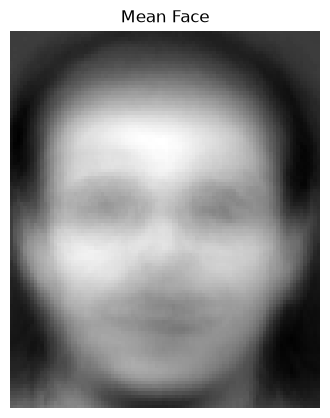

In [19]:
# Calculate the mean face using training images
mean_face = np.mean(X_train, axis=0)

print("Mean face shape:", mean_face.shape)

# Visualize the mean face
plt.figure(figsize=(4, 5))
plt.imshow(mean_face.reshape(112, 92), cmap="gray")
plt.title("Mean Face")
plt.axis("off")
plt.show()

In [20]:
# Center the training data
X_train_centered = X_train - mean_face

print("Centered training matrix shape:", X_train_centered.shape)

# Verify that the mean of each centered feature is approximately zero
print("Mean of first 10 centered features:")
print(np.mean(X_train_centered, axis=0)[:10])

Centered training matrix shape: (280, 10304)
Mean of first 10 centered features:
[-6.49639073e-15 -2.84217094e-15 -6.49639073e-15 -7.00392125e-15
  2.23313431e-15  0.00000000e+00  6.49639073e-15  6.49639073e-15
  9.94759830e-15  4.87229305e-15]


PCA using eigendecomposition

In [21]:

gram_matrix = X_train_centered @ X_train_centered.T

print("Gram matrix shape:", gram_matrix.shape)

eigenvalues, eigenvectors = np.linalg.eigh(gram_matrix)

indices = np.argsort(eigenvalues)[::-1]

eigenvalues = eigenvalues[indices]
eigenvectors = eigenvectors[:, indices]

print("Eigenvalues shape:", eigenvalues.shape)
print("Eigenvectors shape:", eigenvectors.shape)
print("Largest 10 eigenvalues:")
print(eigenvalues[:10])

Gram matrix shape: (280, 280)
Eigenvalues shape: (280,)
Eigenvectors shape: (280, 280)
Largest 10 eigenvalues:
[7.86358179e+08 5.81968800e+08 3.07135446e+08 2.49932620e+08
 2.30965901e+08 1.50817260e+08 1.14020659e+08 1.02117751e+08
 8.98748702e+07 8.31963102e+07]


Converting eigenvectors into eigenfaces

In [22]:
# Keep only positive eigenvalues to avoid division by zero
positive = eigenvalues > 1e-10

eigenvalues = eigenvalues[positive]
eigenvectors = eigenvectors[:, positive]

# Map eigenvectors into pixel space
eigenfaces = (
    X_train_centered.T @ eigenvectors
) / np.sqrt(eigenvalues)[None, :]

print("Eigenfaces matrix shape:", eigenfaces.shape)

Eigenfaces matrix shape: (10304, 279)


Visualizing the first 10 eigenfaces

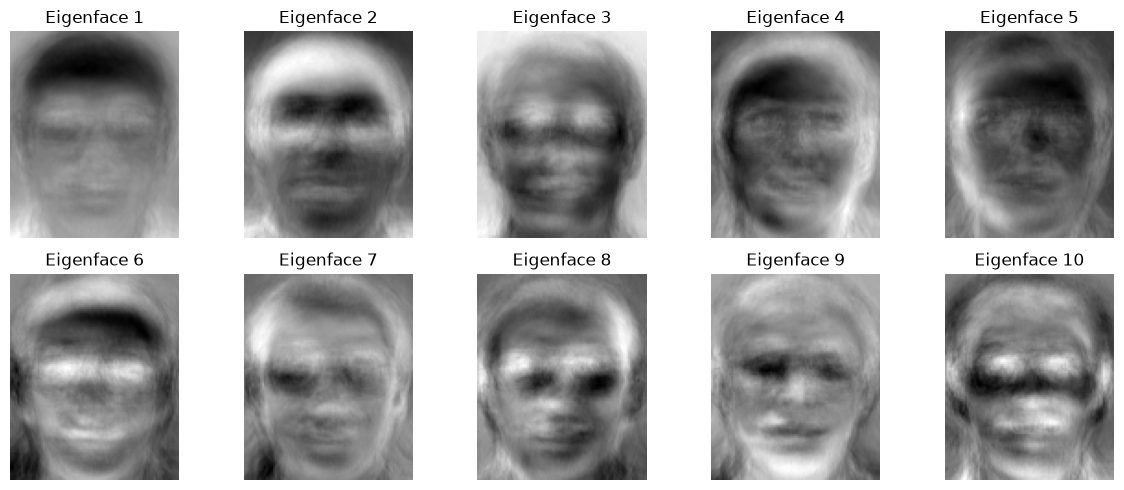

In [23]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    ax.imshow(
        eigenfaces[:, i].reshape(112, 92),
        cmap="gray"
    )
    ax.set_title(f"Eigenface {i + 1}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [24]:

explained_variance_ratio = eigenvalues / np.sum(eigenvalues)

cumulative_variance = np.cumsum(explained_variance_ratio)

print("First 10 explained variance ratios:")
print(explained_variance_ratio[:10])

print("\nFirst 10 cumulative variance values:")
print(cumulative_variance[:10])

First 10 explained variance ratios:
[0.17597634 0.13023676 0.06873277 0.05593155 0.05168705 0.03375087
 0.02551628 0.02285257 0.02011278 0.01861821]

First 10 cumulative variance values:
[0.17597634 0.30621311 0.37494587 0.43087742 0.48256447 0.51631534
 0.54183162 0.56468419 0.58479698 0.60341519]


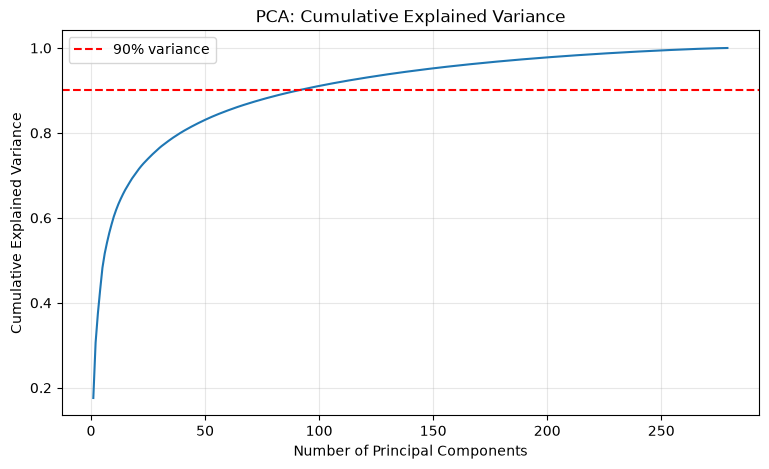

In [25]:
plt.figure(figsize=(9, 5))

plt.plot(
    np.arange(1, len(cumulative_variance) + 1),
    cumulative_variance
)

plt.axhline(y=0.90, color="red", linestyle="--", label="90% variance")

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA: Cumulative Explained Variance")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

minimum number of components for 90% variance

In [26]:
k90 = np.argmax(cumulative_variance >= 0.90) + 1

print("Components required for 90% variance:", k90)
print("Variance retained:", cumulative_variance[k90 - 1])

Components required for 90% variance: 91
Variance retained: 0.9004725047314455


eigendecomposition with SVD

In [27]:
# Compute SVD
U, singular_values, VT = np.linalg.svd(
    X_train_centered,
    full_matrices=False
)

# Principal directions from SVD
components_svd = VT.T

# Eigenvalues corresponding to the singular values
eigenvalues_svd = singular_values ** 2

print("SVD component matrix shape:", components_svd.shape)
print("First 10 SVD eigenvalues:")
print(eigenvalues_svd[:10])

SVD component matrix shape: (10304, 280)
First 10 SVD eigenvalues:
[7.86358179e+08 5.81968800e+08 3.07135446e+08 2.49932620e+08
 2.30965901e+08 1.50817260e+08 1.14020659e+08 1.02117751e+08
 8.98748702e+07 8.31963102e+07]


In [28]:
k_compare = min(10, eigenfaces.shape[1], components_svd.shape[1])

similarities = np.abs(
    np.sum(
        eigenfaces[:, :k_compare] * components_svd[:, :k_compare],
        axis=0
    )
)

print("Absolute similarities between leading directions:")
print(similarities)

Absolute similarities between leading directions:
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


Projecting images into PCA space

In [29]:
# Select the first k90 eigenfaces
selected_eigenfaces = eigenfaces[:, :k90]

# Project training and test images into PCA space
X_train_pca = X_train_centered @ selected_eigenfaces
X_test_pca = (X_test - mean_face) @ selected_eigenfaces

print("Original training shape:", X_train.shape)
print("Reduced training shape:", X_train_pca.shape)

print("Original testing shape:", X_test.shape)
print("Reduced testing shape:", X_test_pca.shape)

Original training shape: (280, 10304)
Reduced training shape: (280, 91)
Original testing shape: (120, 10304)
Reduced testing shape: (120, 91)


Reconstructing sample faces

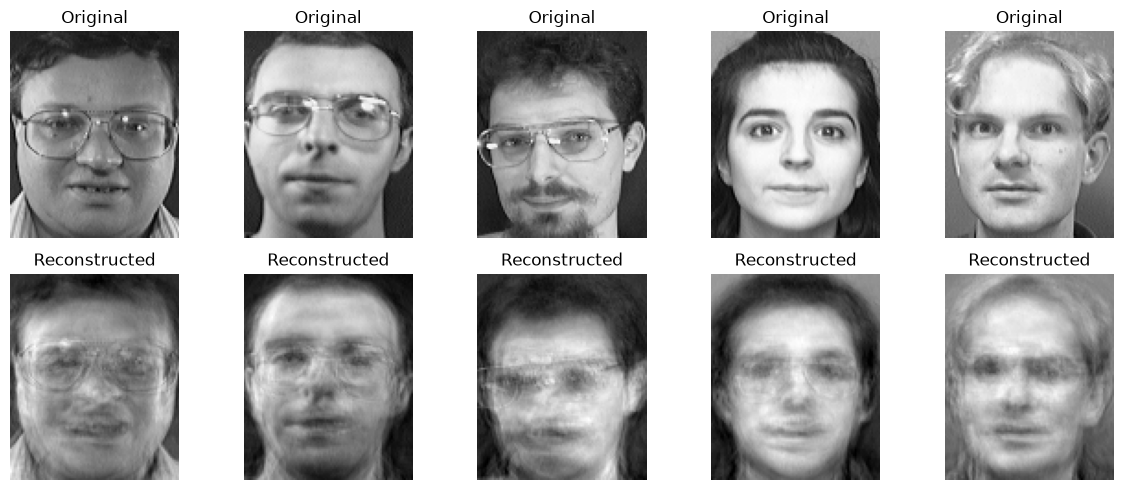

In [30]:
# Reconstruct the first 5 test images
X_test_reconstructed = (
    X_test_pca[:5] @ selected_eigenfaces.T
) + mean_face

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i in range(5):
    axes[0, i].imshow(X_test[i].reshape(112, 92), cmap="gray")
    axes[0, i].set_title("Original")
    axes[0, i].axis("off")

    axes[1, i].imshow(
        np.clip(X_test_reconstructed[i].reshape(112, 92), 0, 255),
        cmap="gray"
    )
    axes[1, i].set_title("Reconstructed")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()

In [31]:
rmse = np.sqrt(
    np.mean((X_test[:5] - X_test_reconstructed) ** 2)
)

print("Reconstruction RMSE:", rmse)

Reconstruction RMSE: 19.714274642284607


In [32]:
original_features = X_train.shape[1]
reduced_features = k90

reduction_percentage = (
    1 - reduced_features / original_features
) * 100

print("Original features per image:", original_features)
print("Reduced features per image:", reduced_features)
print(f"Feature reduction: {reduction_percentage:.2f}%")

Original features per image: 10304
Reduced features per image: 91
Feature reduction: 99.12%


Implementing Euclidean distance matching

In [33]:
# Store predictions for PCA-based recognition
pca_predictions = []

for test_face in X_test_pca:

    # Calculate Euclidean distance from this test face
    # to every training face in PCA space
    distances = np.sqrt(
        np.sum((X_train_pca - test_face) ** 2, axis=1)
    )

    # Index of the closest training face
    nearest_index = np.argmin(distances)

    # Predict its subject label
    predicted_label = y_train[nearest_index]

    pca_predictions.append(predicted_label)

pca_predictions = np.array(pca_predictions)

print("Actual labels:", y_test[:10])
print("Predicted labels:", pca_predictions[:10])

Actual labels: [31 19 17 10 18 25 18 38 37 38]
Predicted labels: [31 19 17 38 18 25 18 38 37 23]


In [34]:
from sklearn.metrics import accuracy_score, confusion_matrix

pca_accuracy = accuracy_score(y_test, pca_predictions)

print(f"PCA recognition accuracy: {pca_accuracy * 100:.2f}%")

PCA recognition accuracy: 96.67%


Compare with raw-pixel recognition

In [35]:
raw_predictions = []

for test_face in X_test:

    distances = np.sqrt(
        np.sum((X_train - test_face) ** 2, axis=1)
    )

    nearest_index = np.argmin(distances)
    raw_predictions.append(y_train[nearest_index])

raw_predictions = np.array(raw_predictions)

raw_accuracy = accuracy_score(y_test, raw_predictions)

print(f"Raw-pixel accuracy: {raw_accuracy * 100:.2f}%")
print(f"PCA-based accuracy: {pca_accuracy * 100:.2f}%")

Raw-pixel accuracy: 99.17%
PCA-based accuracy: 96.67%


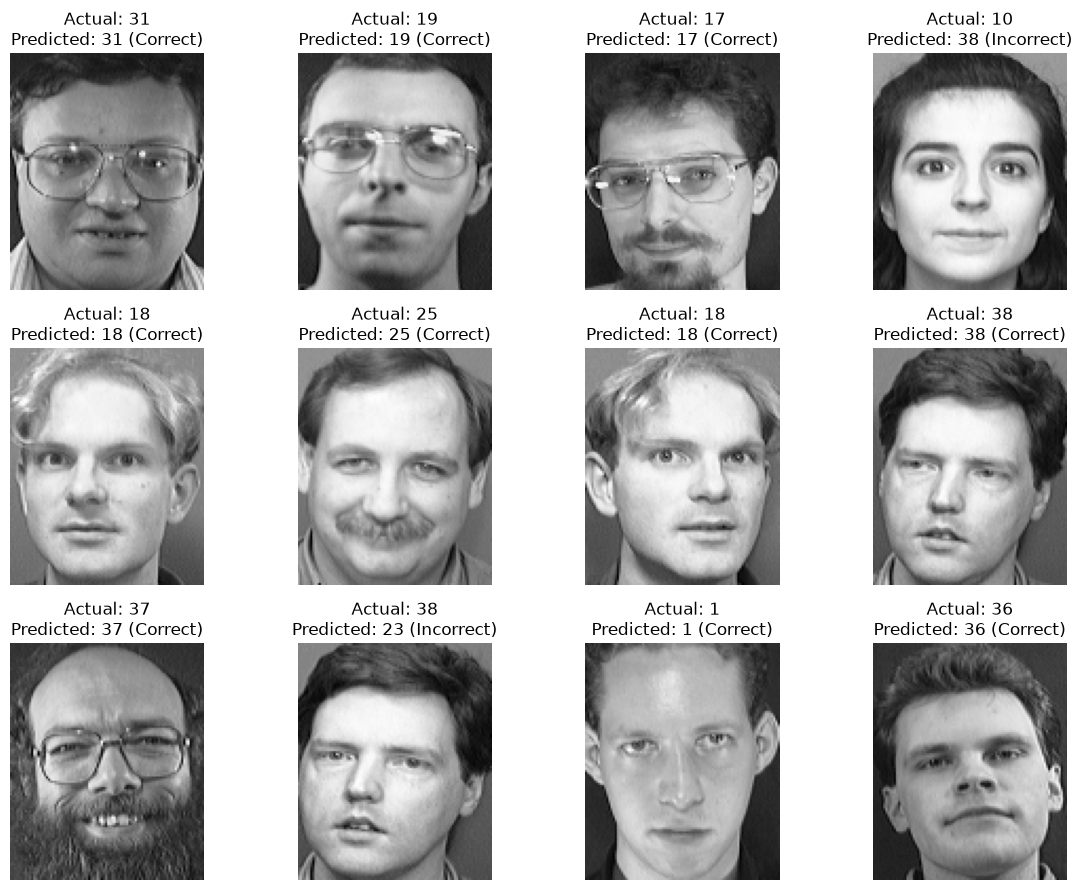

In [36]:
fig, axes = plt.subplots(3, 4, figsize=(12, 9))

for i, ax in enumerate(axes.flat):
    if i >= len(X_test):
        ax.axis("off")
        continue

    ax.imshow(X_test[i].reshape(112, 92), cmap="gray")

    actual = y_test[i]
    predicted = pca_predictions[i]

    result = "Correct" if actual == predicted else "Incorrect"

    ax.set_title(
        f"Actual: {actual}\nPredicted: {predicted} ({result})"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

In [37]:
import pandas as pd

comparison = pd.DataFrame({
    "Method": [
        "Nearest Neighbor - Raw Pixels",
        "Nearest Neighbor - PCA"
    ],
    "Accuracy (%)": [
        raw_accuracy * 100,
        pca_accuracy * 100
    ]
})

print(comparison.to_string(index=False))

                       Method  Accuracy (%)
Nearest Neighbor - Raw Pixels     99.166667
       Nearest Neighbor - PCA     96.666667


KNN classifier

In [38]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

knn = KNeighborsClassifier(n_neighbors=3)

knn.fit(X_train_pca, y_train)

knn_predictions = knn.predict(X_test_pca)

knn_accuracy = accuracy_score(y_test, knn_predictions)

print(f"KNN Accuracy: {knn_accuracy * 100:.2f}%")

KNN Accuracy: 94.17%


Training Logistic Regression

In [39]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

logistic_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=3000, random_state=42)
)

logistic_model.fit(X_train_pca, y_train)

logistic_predictions = logistic_model.predict(X_test_pca)

logistic_accuracy = accuracy_score(
    y_test, logistic_predictions
)

print(f"Logistic Regression Accuracy: {logistic_accuracy * 100:.2f}%")

Logistic Regression Accuracy: 92.50%


Training an SVM classifier

In [40]:
from sklearn.svm import SVC

svm_model = make_pipeline(
    StandardScaler(),
    SVC(kernel="rbf", C=10, gamma="scale")
)

svm_model.fit(X_train_pca, y_train)

svm_predictions = svm_model.predict(X_test_pca)

svm_accuracy = accuracy_score(y_test, svm_predictions)

print(f"SVM Accuracy: {svm_accuracy * 100:.2f}%")

SVM Accuracy: 95.00%


Comparing all recognition methods

In [42]:
import pandas as pd

results = pd.DataFrame({
    "Method": [
        "Nearest Neighbor - Raw Pixels",
        "Nearest Neighbor - PCA",
        "KNN - PCA",
        "Logistic Regression - PCA",
        "SVM - PCA"
    ],
    "Accuracy (%)": [
        raw_accuracy * 100,
        pca_accuracy * 100,
        knn_accuracy * 100,
        logistic_accuracy * 100,
        svm_accuracy * 100
    ]
})

results = results.sort_values(
    by="Accuracy (%)",
    ascending=False
).reset_index(drop=True)

print(results.to_string(index=False))

                       Method  Accuracy (%)
Nearest Neighbor - Raw Pixels     99.166667
       Nearest Neighbor - PCA     96.666667
                    SVM - PCA     95.000000
                    KNN - PCA     94.166667
    Logistic Regression - PCA     92.500000


Experiment with the number of PCA components

In [43]:
component_counts = [
    k for k in [10, 20, 30, 40, 50, k90]
    if k <= eigenfaces.shape[1]
]

component_counts = sorted(set(component_counts))
experiment_results = []

for k in component_counts:

    train_features = (
        X_train - mean_face
    ) @ eigenfaces[:, :k]

    test_features = (
        X_test - mean_face
    ) @ eigenfaces[:, :k]

    model = KNeighborsClassifier(n_neighbors=3)
    model.fit(train_features, y_train)

    predictions = model.predict(test_features)
    accuracy = accuracy_score(y_test, predictions)

    experiment_results.append({
        "Components": k,
        "Variance Retained (%)": cumulative_variance[k - 1] * 100,
        "KNN Accuracy (%)": accuracy * 100
    })

experiment_df = pd.DataFrame(experiment_results)
print(experiment_df.to_string(index=False))

 Components  Variance Retained (%)  KNN Accuracy (%)
         10              60.341519         86.666667
         20              70.806944         90.833333
         30              76.479771         93.333333
         40              80.277865         94.166667
         50              83.085844         94.166667
         91              90.047250         94.166667


Plot accuracy against component count

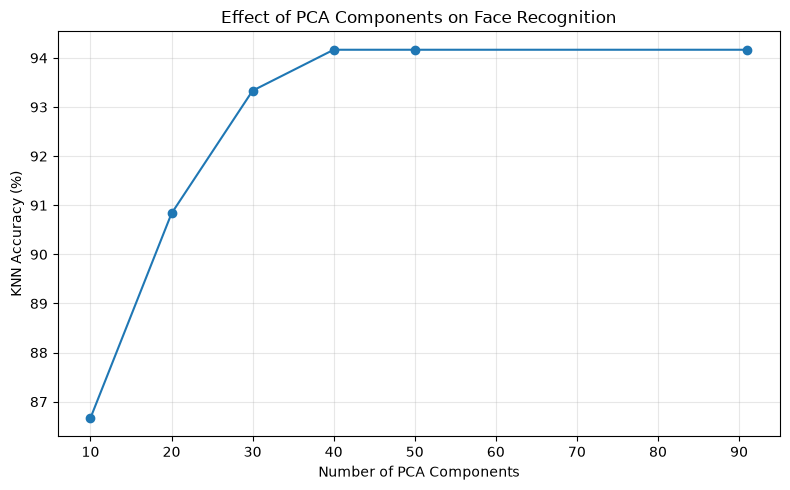

In [44]:
plt.figure(figsize=(8, 5))

plt.plot(
    experiment_df["Components"],
    experiment_df["KNN Accuracy (%)"],
    marker="o"
)

plt.xlabel("Number of PCA Components")
plt.ylabel("KNN Accuracy (%)")
plt.title("Effect of PCA Components on Face Recognition")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [45]:
from pathlib import Path

output_path = Path("outputs")
output_path.mkdir(parents=True, exist_ok=True)

print("Output folder:", output_path.resolve())

Output folder: C:\Users\Yashish\OneDrive\Desktop\202618019_JayeshHedaoo_DS605\202618019_LAB07\outputs


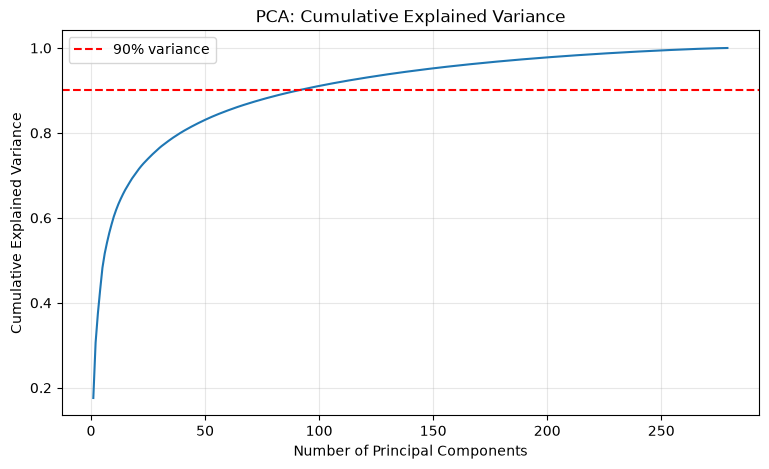

Comparison table saved successfully.
Files saved in outputs:
comparison_results.csv
explained_variance.png


In [47]:
plt.figure(figsize=(9, 5))

plt.plot(
    np.arange(1, len(cumulative_variance) + 1),
    cumulative_variance
)

plt.axhline(
    y=0.90,
    color="red",
    linestyle="--",
    label="90% variance"
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA: Cumulative Explained Variance")
plt.grid(True, alpha=0.3)
plt.legend()

plt.savefig(
    output_path / "explained_variance.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

results.to_csv(
    output_path / "comparison_results.csv",
    index=False
)

print("Comparison table saved successfully.")

print("Files saved in outputs:")

for file in sorted(output_path.iterdir()):
    print(file.name)

In [49]:
plt.savefig(
    output_path / "eigenfaces.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

plt.savefig(
    output_path / "reconstruction.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

plt.savefig(
    output_path / "recognition_results.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

plt.savefig(
    output_path / "accuracy_vs_components.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

from pathlib import Path

output_path = Path("outputs")
output_path.mkdir(exist_ok=True)

for file in sorted(output_path.iterdir()):
    print(file.name)

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

accuracy_vs_components.png
comparison_results.csv
eigenfaces.png
explained_variance.png
recognition_results.png
reconstruction.png
